In [2]:
from pathlib import Path
from parse import parse
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib as mpl
from matplotlib import ticker
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import scipy.stats as stats
from statistics import mean
import math

In [3]:
qpcrPath = Path(r'C:\Users\MVX\OneDrive - UW\Allbritton Lab\Genetic Analysis\2024_06_20_NOG&KRT7.csv')
# qpcrPath = Path(r'C:\Users\ianja\OneDrive - UW\Allbritton Lab\Genetic Analysis\2024_06_20_NOG&KRT7.csv')
df_raw = pd.read_csv(str(qpcrPath))

plate_set = ['NOG', 'KRT7']
arr_set = ['1', '2', '3']
ploid_set = ['Eu', 'An']
num_set = ['1', '2', '3']
target_set = [['GAPDH', 'NOG'], ['GAPDH', 'KRT7']]

arrs = []
ploids = []
samp_nums = []
pattern = '{arr}_{ploid}_{num}'
for samp in df_raw['Sample Name'].tolist():
    patternResult = parse(pattern, samp)
    arrs.append(patternResult['arr'])
    ploids.append(patternResult['ploid'])
    samp_nums.append(patternResult['num'])
df_raw['Arr'] = arrs
df_raw['Ploid'] = ploids
df_raw['Samp_Num'] = samp_nums
# print(df_raw.head(20))

plates2 = []
arrs2 = []
ploids2 = []
samp_nums2 = []
targets2 = []
means_CT = []
for i in range(len(plate_set)):
    for a in arr_set:
        for p in ploid_set:
            for n in num_set:
                for t in target_set[i]:
#                     df_sub = df_raw[(df_raw['Plate']==plate_set[i])
#                                     & (df_raw['Arr']==a) 
#                                     & (df_raw['Ploid']==p) 
#                                     & (df_raw['Samp_Num']==n) 
#                                     & (df_raw['Target Name']==t)
#                                    ]
                    df_sub = df_raw[(df_raw['Arr']==a) 
                                    & (df_raw['Ploid']==p) 
                                    & (df_raw['Samp_Num']==n) 
                                    & (df_raw['Target Name']==t)
                                   ]
#                     print(df_sub.head())
                    plates2.append(plate_set[i])
                    arrs2.append(a)
                    ploids2.append(p)
                    samp_nums2.append(n)
                    targets2.append(t)
#                     print(f'Plate {plate_set[i]}, {a}_{p}_{n}, Target {t}')
#                     print(df_sub['CT'].tolist())
                    mean_CT = mean(df_sub['CT'].tolist())
                    means_CT.append(mean_CT)
df_mean_CT = pd.DataFrame({'Plate': plates2,
                           'Arr': arrs2,
                           'Ploid': ploids2,
                           'Samp_Num': samp_nums2,
                           'Target': targets2,
                           'Mean_CT': means_CT
                          })
# print(df_mean_CT)

samp_names3 = []
arrs3 = []
ploids3 = []
samp_nums3 = []
targets3 = []
dCTs = []

for pl in plate_set:
    for a in arr_set:
        for p in ploid_set:
            for n in num_set:
                df_sub = df_mean_CT[(df_mean_CT['Plate']==pl)
                                    & (df_mean_CT['Arr']==a) 
                                    & (df_mean_CT['Ploid']==p) 
                                    & (df_mean_CT['Samp_Num']==n)
                                ]
                gapdh = df_sub[df_sub['Target']=='GAPDH']['Mean_CT'].item()
                if pl == 'NOG':
                    goi = df_sub[df_sub['Target']=='NOG']['Mean_CT'].item()
                elif pl == 'KRT7':
                    goi = df_sub[df_sub['Target']=='KRT7']['Mean_CT'].item()
                
                samp_names3.append(f'{a}_{p}_{n}')
                arrs3.append(a)
                ploids3.append(p)
                samp_nums3.append(n)
                targets3.append(pl)
                dCTs.append(goi - gapdh)
df_final = pd.DataFrame({'Samp_Name': samp_names3,
                         'Arr': arrs3,
                        'Ploid': ploids3,
                        'Samp_Num': samp_nums3,
                        'Target': targets3,
                        'dCT': dCTs
                        })
# print(df_final)

ctrl_dCTs = []
ddCTs = []
rel_exps = []
for t in plate_set:
    for a in arr_set:
        df_sub1 = df_final[(df_final['Arr']==a)
                         & (df_final['Ploid']=='Eu')
                         & (df_final['Target']==t)]
        dCT_ctrl = mean(df_sub1['dCT'].tolist())
        for p in ploid_set:
            for n in num_set:
                ctrl_dCTs.append(dCT_ctrl)
                df_sub2 = df_final[(df_final['Arr']==a)
                                   & (df_final['Ploid']==p)
                                   & (df_final['Samp_Num']==n)
                                   & (df_final['Target']==t)
                                  ]
                dCT = df_sub2['dCT'].item()
                ddCT = dCT - dCT_ctrl
                ddCTs.append(ddCT)
                rel_exp = 2 ** (-ddCT)
                rel_exps.append(rel_exp)
            
df_final['Average dCT'] = ctrl_dCTs
df_final['ddCTs'] = ddCTs
df_final['2^-ddCT'] = rel_exps
print(df_final.head())

df_final2 = df_final[~((df_final['Arr']=='3')
                    & (df_final['Ploid']=='An')
                    & (df_final['Samp_Num']=='1')
                    & (df_final['Target']=='NOG'))
                   ]

# outPath = Path(r'C:\Users\MVX\OneDrive - UW\Allbritton Lab\Genetic Analysis\2024_06_20_NOG&KRT7_RelExp.csv')
# outPath = Path(r'C:\Users\ianja\OneDrive - UW\Allbritton Lab\Genetic Analysis\2024_06_20_NOG&KRT7_RelExp.csv')
# df_final2.to_csv(outPath, header=True, index=False)

arrs4 = []
ploids4 = []
targets4 = []
means_relexp = []
for a in arr_set:
    for p in ploid_set:
        for t in plate_set:
            df_sub = df_final2[(df_final2['Arr']==a)
                              & (df_final2['Ploid']==p)
                              & (df_final2['Target']==t)
                             ]
            arrs4.append(a)
            ploids4.append(p)
            targets4.append(t)
            mean_relexp = mean(df_sub['2^-ddCT'].tolist())
            means_relexp.append(mean_relexp)
df_mean_relexp = pd.DataFrame({'Arr': arrs4,
                               'Ploid': ploids4,
                               'Target': targets4,
                               'Mean_RelExp': means_relexp
                              })
ttest_nog = stats.ttest_ind(a=df_mean_relexp[(df_mean_relexp['Ploid']=='Eu')
                                             & (df_mean_relexp['Target']=='NOG')]['Mean_RelExp'],
                            b=df_mean_relexp[(df_mean_relexp['Ploid']=='An')
                                             & (df_mean_relexp['Target']=='NOG')]['Mean_RelExp'],
                            equal_var=True)
ttest_krt = stats.ttest_ind(a=df_mean_relexp[(df_mean_relexp['Ploid']=='Eu')
                                             & (df_mean_relexp['Target']=='KRT7')]['Mean_RelExp'],
                            b=df_mean_relexp[(df_mean_relexp['Ploid']=='An')
                                             & (df_mean_relexp['Target']=='KRT7')]['Mean_RelExp'],
                            equal_var=True)
print(f'NOG: {ttest_nog}')
print(f'KRT7: {ttest_krt}')
# print(df_mean_relexp)

  Samp_Name Arr Ploid Samp_Num Target        dCT  Average dCT     ddCTs  \
0    1_Eu_1   1    Eu        1    NOG  11.280500    10.919611  0.360889   
1    1_Eu_2   1    Eu        2    NOG  10.981500    10.919611  0.061889   
2    1_Eu_3   1    Eu        3    NOG  10.496833    10.919611 -0.422778   
3    1_An_1   1    An        1    NOG   8.709500    10.919611 -2.210111   
4    1_An_2   1    An        2    NOG   9.730000    10.919611 -1.189611   

    2^-ddCT  
0  0.778685  
1  0.958009  
2  1.340506  
3  4.627109  
4  2.280913  
NOG: Ttest_indResult(statistic=-4.481738125969077, pvalue=0.010975189324397998)
KRT7: Ttest_indResult(statistic=-22.48293423454293, pvalue=2.3175713143046085e-05)


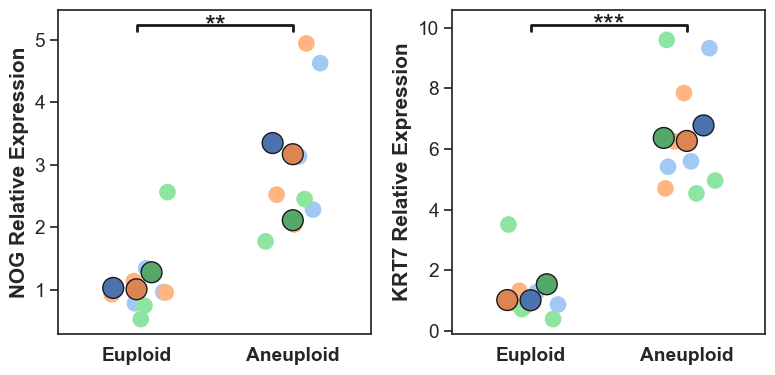

In [7]:
sns.set_style('white')
plt.rcParams['ytick.left'] = True

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

sns.stripplot(ax=axes[0],
              x='Ploid',
              y='2^-ddCT',
              data = df_final2[df_final2['Target']=='NOG'],
              hue='Arr',
              size=12,
              palette='pastel',
              jitter=0.2,
              legend=False,
              zorder=1)
sns.swarmplot(ax=axes[0],
              x='Ploid',
              y='Mean_RelExp',
              data= df_mean_relexp[df_mean_relexp['Target']=='NOG'],
              hue='Arr',
              size=15,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False,
              zorder=2)
axes[0].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[0].set_xlabel('', fontweight='bold')
axes[0].set_ylabel('NOG Relative Expression', fontweight='bold')
axes[0].set_xlim(-0.5,1.5)

sns.stripplot(ax=axes[1],
              x='Ploid',
              y='2^-ddCT',
              data = df_final2[df_final2['Target']=='KRT7'],
              hue='Arr',
              size=12,
              palette='pastel',
              jitter=0.2,
              legend=False,
              zorder=1)
sns.swarmplot(ax=axes[1],
              x='Ploid',
              y='Mean_RelExp',
              data= df_mean_relexp[df_mean_relexp['Target']=='KRT7'],
              hue='Arr',
              size=15,
              palette='deep',
              edgecolor='k',
              linewidth=1,
              legend=False,
              zorder=2)
axes[1].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[1].set_xlabel('', fontweight='bold')
axes[1].set_ylabel('KRT7 Relative Expression', fontweight='bold')
axes[1].set_xlim(-0.5,1.5)
# axes[1].set_ylim(0,18)
# axes[1].set_yticks(range(0,15,5))

nog = [float(i) for i in df_final2[df_final2['Target']=='NOG']['2^-ddCT'].tolist()]
axes[0].plot([0, 0, 1, 1], 
             [max(nog)+0.2, 
              max(nog)+0.3, 
              max(nog)+0.3, 
              max(nog)+0.2], 
             linewidth=2, 
             color='k')
axes[0].text((0+1)*0.5, 
             max(nog)+0.05,
             "**", 
             ha='center', 
             va='bottom', 
             color='k',
             fontsize=20
            )
krt = [float(i) for i in df_final2[df_final2['Target']=='KRT7']['2^-ddCT'].tolist()]
axes[1].plot([0, 0, 1, 1], 
             [max(krt)+0.3, 
              max(krt)+0.5, 
              max(krt)+0.5, 
              max(krt)+0.3], 
             linewidth=2, 
             color='k')
axes[1].text((0+1)*0.5, 
             max(krt)+0.02,
             "***", 
             ha='center', 
             va='bottom', 
             color='k',
             fontsize=20
            )

sns.set(font_scale=1.25)
fig.tight_layout()

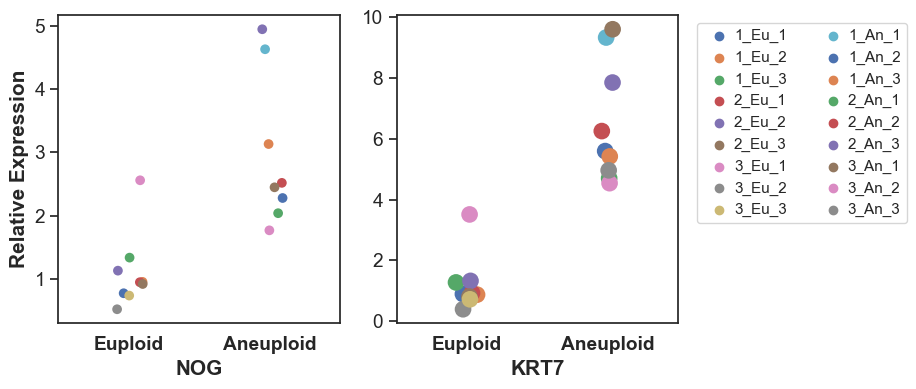

In [15]:
sns.set_style('white')
plt.rcParams['ytick.left'] = True

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

df_final = df_final.sort_values(by=['Ploid', 'Arr', 'Samp_Num'],
                                ascending=[False, True, True]
                               )

sns.stripplot(ax=axes[0],
              x='Ploid',
              y='2^-ddCT',
              data = df_final2[df_final2['Target']=='NOG'],
              hue='Samp_Name',
              size=7,
              palette='deep',
              jitter=0.1,
              legend=False,
              zorder=1)
axes[0].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[0].set_ylabel('Relative Expression', fontweight='bold')
axes[0].set_xlabel('NOG', fontweight='bold')
# axes[0].set_ylim(0,6)

sns.stripplot(ax=axes[1],
              x='Ploid',
              y='2^-ddCT',
              data = df_final2[df_final2['Target']=='KRT7'],
              hue='Samp_Name',
              size=12,
              palette='deep',
              jitter=0.1,
              zorder=1)
axes[1].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xlabel('KRT7', fontweight='bold')
# axes[1].set_ylim(0,10)
# axes[1].set_yticks(range(0,19,5))

plt.legend(bbox_to_anchor=(1.04, 1),
           ncols=2,
           handletextpad=0,
           fontsize=11)

sns.set(font_scale=1.25)
# fig.tight_layout()

In [ ]:
sns.set_style('white')
plt.rcParams['ytick.left'] = True

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

df_raw = df_raw.sort_values(by=['Ploid', 'Arr', 'Samp_Num'],
                            ascending=[False, True, True]
                           )
print(df_raw.head())

sns.stripplot(ax=axes[0],
              x='Ploid',
              y='CT',
              data = df_raw[(df_raw['Plate']=='NOG')
                            & (df_raw['Target Name']=='GAPDH')],
              hue='Sample Name',
              size=7,
              palette='deep',
              jitter=0.2,
              legend=False,
              zorder=1)
axes[0].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[0].set_ylabel('CT (GAPDH)', fontweight='bold')
axes[0].set_xlabel('NOG Plate', fontweight='bold')
# axes[0].set_ylim(0,6)

sns.stripplot(ax=axes[1],
             x='Ploid',
              y='CT',
              data = df_raw[(df_raw['Plate']=='KRT7')
                            & (df_raw['Target Name']=='GAPDH')],
              hue='Sample Name',
              size=7,
              palette='deep',
              jitter=0.2,
              zorder=1)
axes[1].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xlabel('KRT7 Plate', fontweight='bold')
# axes[1].set_ylim(0,10)

plt.legend(bbox_to_anchor=(1.04, 1),
           ncols=2,
           handletextpad=0,
           fontsize=11)

sns.set(font_scale=1.25)

In [ ]:
sns.set_style('white')
plt.rcParams['ytick.left'] = True

fig, axes = plt.subplots(1, 1, figsize=(4, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

df_raw = df_raw.sort_values(by=['Ploid', 'Arr', 'Samp_Num'],
                            ascending=[False, True, True]
                           )
print(df_raw.head())

sns.stripplot(ax=axes,
              x='Ploid',
              y='CT',
              data = df_raw[df_raw['Target Name']=='GAPDH'],
              hue='Sample Name',
              size=7,
              palette='deep',
              jitter=0.2,
              legend=True,
              zorder=1)
axes.set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes.set_ylabel('CT (GAPDH)', fontweight='bold')
axes.set_xlabel('', fontweight='bold')

plt.legend(bbox_to_anchor=(1.04, 1),
           ncols=2,
           handletextpad=0,
           fontsize=11)

In [ ]:
sns.set_style('white')
plt.rcParams['ytick.left'] = True

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.set_style('white')
plt.rcParams['ytick.left'] = True

df_final = df_final.sort_values(by=['Ploid', 'Arr', 'Samp_Num'],
                                ascending=[False, True, True]
                               )


sns.stripplot(ax=axes[0],
              x='Ploid',
              y='dCT',
              data = df_final[df_final['Target']=='NOG'],
              hue='Samp_Name',
              size=7,
              palette='deep',
              jitter=0.2,
              legend=False,
              zorder=1)
axes[0].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[0].set_ylabel('dCT', fontweight='bold')
axes[0].set_xlabel('NOG', fontweight='bold')
# axes[0].set_ylim(0,6)

sns.stripplot(ax=axes[1],
              x='Ploid',
              y='dCT',
              data = df_final[df_final['Target']=='KRT7'],
              hue='Samp_Name',
              size=7,
              palette='deep',
              jitter=0.2,
              zorder=1)
axes[1].set_xticks([0, 1], ['Euploid', 'Aneuploid'], fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xlabel('KRT7', fontweight='bold')
# axes[1].set_ylim(0,10)

plt.legend(bbox_to_anchor=(1.04, 1),
           ncols=2,
           handletextpad=0,
           fontsize=11)

sns.set(font_scale=1.25)

NOG: PearsonRResult(statistic=-0.6896534952984287, pvalue=0.0021899022848570347)
KRT7: PearsonRResult(statistic=-0.8809242350518294, pvalue=1.389905531749792e-06)


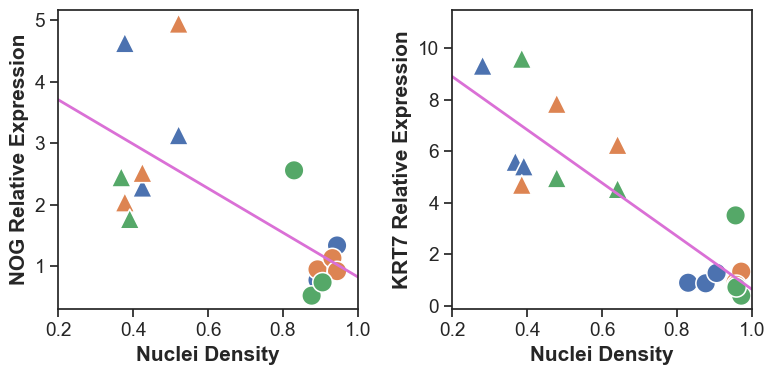

In [32]:
nucPaths = [Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240605_RUES2_1.8e6_48hrBMP4_0&100%aneu_5_Analysis'),
            Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240612_RUES2_1.8e6_48hrBMP4_0&100%aneu_6_Analysis'),
            Path(r'C:\Users\MVX\Documents\2 - Data\Analysis\240619_RUES2_1.8e6_48hrBMP4_0&100%aneu_7_Analysis'),
           ]
rafts_eu = [[484, 284, 75],
         [466, 480, 433],
         [189, 314, 331]
        ]
rafts_an = [[222, 178, 332],
         [268, 195, 127],
         [40, 125, 154]
        ]

nucDens = []
for a in arr_set:
    for target in plate_set:
        for p in ploid_set:
            for n in num_set:
                if p == 'Eu':
                    df_fluor = pd.read_csv(str(nucPaths[int(a) - 1] / 'array1_FluorAnalysis_CalcHoechst.csv'))
                    raft = rafts_eu[int(a) - 1][int(n) - 1]
                elif p == 'An':
                    df_fluor = pd.read_csv(str(nucPaths[int(a) - 1] / 'array2_FluorAnalysis_CalcHoechst.csv'))
                    raft = rafts_an[int(a) - 1][int(n) - 1]
                nucDen = df_fluor[df_fluor['Raft']==raft]['NucDen'].item()
                nucDens.append(nucDen)
df_final['NucDen'] = nucDens

df_final2 = df_final[~((df_final['Arr']=='3')
                       & (df_final['Ploid']=='An')
                       & (df_final['Samp_Num']=='1')
                       & (df_final['Target']=='NOG'))
                    ]

# print(df_final2.head(10))

sns.set_theme(style='ticks', font_scale=1.25)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

size = 200
data_nog = df_final2[(df_final2['Target']=='NOG')]
sns.scatterplot(ax=axes[0],
                x='NucDen',
                y='2^-ddCT',
                data=data_nog[data_nog['Ploid']=='Eu'],
                marker='o',
                s=size,
                hue='Arr',
                legend=False)
sns.scatterplot(ax=axes[0],
                x='NucDen',
                y='2^-ddCT',
                data=data_nog[data_nog['Ploid']=='An'],
                marker='^',
                s=size,
                hue='Arr',
                legend=False)
m, b = np.polyfit(data_nog['NucDen'], data_nog['2^-ddCT'], 1)
# X_plot = np.linspace(axes[0].get_xlim()[0],axes[0].get_xlim()[1],100)
X_plot = np.linspace(0,1,100)
axes[0].plot(X_plot, m*X_plot + b, '-', color='orchid', linewidth=2)
axes[0].set_xlabel('Nuclei Density', fontweight='bold')
axes[0].set_ylabel('NOG Relative Expression', fontweight='bold')
axes[0].set_xlim(0.2,1)

data_krt = df_final2[(df_final2['Target']=='KRT7')]
sns.scatterplot(ax=axes[1],
                x='NucDen',
                y='2^-ddCT',
                data=data_krt[data_krt['Ploid']=='Eu'],
                marker='o',
                s=size,
                hue='Arr',
                legend=False)
sns.scatterplot(ax=axes[1],
                x='NucDen',
                y='2^-ddCT',
                data=data_krt[data_krt['Ploid']=='An'],
                marker='^',
                s=size,
                hue='Arr',
                legend=False)
m, b = np.polyfit(data_krt['NucDen'], data_krt['2^-ddCT'], 1)
# X_plot = np.linspace(axes[0].get_xlim()[0],axes[0].get_xlim()[1],100)
X_plot = np.linspace(0,1,100)
axes[1].plot(X_plot, m*X_plot + b, '-', color='orchid', linewidth=2)
axes[1].set_xlabel('Nuclei Density', fontweight='bold')
axes[1].set_ylabel('KRT7 Relative Expression', fontweight='bold')
axes[1].set_xlim(0.2,1)

pearson_nog = stats.pearsonr(df_final2[df_final2['Target']=='NOG']['NucDen'],
                             df_final2[df_final2['Target']=='NOG']['2^-ddCT'])
pearson_krt = stats.pearsonr(df_final2[df_final2['Target']=='KRT7']['NucDen'],
                             df_final2[df_final2['Target']=='KRT7']['2^-ddCT'])

print(f'NOG: {pearson_nog}')
print(f'KRT7: {pearson_krt}')

fig.tight_layout()